In [1]:
!pip install --upgrade --no-cache-dir pykrx
from pykrx import stock
from datetime import date
import time
import pandas as pd
import numpy as np
import requests

You should consider upgrading via the '/Users/mingeonsung/esg-investment/venv/bin/python3 -m pip install --upgrade pip' command.
KRX 로그인 실패: KRX_ID 또는 KRX_PW 환경 변수가 설정되지 않았습니다.


In [2]:
# 날짜 설정
today = date.today().strftime("%Y%m%d")
start_date = "20210101"  # 5년치 확보 (252일 룰 적용에 충분)
end_date = today

print(f"Data range: {start_date} ~ {end_date}")

tickers = ["069500","229200","132030","219480","379810","192090","195980","251350",
           "352560","195930","245360","314250","289250","290130","379800","228790",
           "462010","371160","466920","457480","305720","371460","449450","494670",
           "487240","458730","483320","381180","487230","498400","091160"]

price = pd.DataFrame()
print("데이터 다운로드 시작...")
for ticker in tickers:
    df = stock.get_market_ohlcv_by_date(start_date, end_date, ticker)
    if not df.empty:
        price = pd.concat([price, df["종가"].rename(ticker)], axis=1)
        print(f"{ticker} 완료")
    else:
        print(f"데이터 없음: {ticker}")
    time.sleep(0.05)

price.to_csv("outputs/price.csv", encoding="utf-8-sig")
print(f"price.csv 저장! ({price.shape[0]}일 x {price.shape[1]}개 ETF)")
display(price.tail())

Data range: 20210101 ~ 20260604
데이터 다운로드 시작...
069500 완료
229200 완료
132030 완료
219480 완료
379810 완료
192090 완료
195980 완료
251350 완료
352560 완료
195930 완료
245360 완료
314250 완료
289250 완료
290130 완료
379800 완료
228790 완료
462010 완료
371160 완료
466920 완료
457480 완료
305720 완료
371460 완료
449450 완료
494670 완료
487240 완료
458730 완료
483320 완료
381180 완료
487230 완료
498400 완료
091160 완료
price.csv 저장! (1327일 x 31개 ETF)


,069500,229200,132030,219480,379810,192090,195980,251350,352560,195930,...,371460,449450,494670,487240,458730,483320,381180,487230,498400,091160
2026-05-28 00:00:00,129990,19120,24790,32525,29760.0,14315,15195,41320,12450,22005,...,13755,70125.0,30125.0,48565.0,15535.0,28325.0,49355.0,25800.0,25655.0,160810
2026-05-29 00:00:00,134815,18730,25535,32805,30250.0,14400,15480,41925,12365,22125,...,13700,68130.0,29780.0,47220.0,15540.0,29225.0,50825.0,25890.0,26545.0,160980
2026-06-01 00:00:00,141395,18410,25530,32920,30435.0,14205,15705,42020,12280,22190,...,13500,67995.0,29470.0,50170.0,15450.0,29645.0,51220.0,25605.0,27800.0,165410
2026-06-02 00:00:00,141575,17955,25650,32830,30605.0,14515,15725,42000,12015,22370,...,13800,63510.0,28375.0,46280.0,15405.0,30825.0,51755.0,25335.0,27825.0,163875
2026-06-04 00:00:00,138465,18655,25235,32595,30860.0,14660,15495,42840,12065,21990,...,13495,61430.0,28190.0,46417.0,15650.0,30725.0,54667.0,26280.0,27240.0,169465


In [3]:
import re
import pandas as pd
import requests

# 1. 티커-종목명 매핑 생성
def fetch_etf_name(ticker):
    if not re.match(r'^\d{6}$', str(ticker)):
        return str(ticker)
    try:
        url = f'https://m.stock.naver.com/api/stock/{ticker}/basic'
        resp = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=5)
        if resp.ok:
            return resp.json().get('stockName', ticker)
    except Exception:
        pass
    return ticker

ticker_map = {ticker: fetch_etf_name(ticker) for ticker in price.columns}

# 2. 변환 함수
def get_name(ticker):
    return ticker_map.get(ticker, ticker) # 매핑에 없는 경우 티커 자체 반환

# price.csv 파일 로드 (이전 셀에서 생성된 파일)
price = pd.read_csv('outputs/price.csv', index_col=0)

# 컬럼명(티커 코드)을 종목명으로 변환
price.columns = [get_name(col) for col in price.columns]

# 변환된 DataFrame 상위 5행 표시
display(price.head())

,KODEX 200,KODEX 코스닥150,KODEX 골드선물(H),KODEX 미국S&P500선물(H),KODEX 미국나스닥100,TIGER 차이나CSI300,PLUS 신흥국MSCI(합성 H),KODEX MSCI선진국,KODEX 미국부동산리츠(H),TIGER 유로스탁스50(합성 H),...,TIGER 차이나전기차SOLACTIVE,PLUS K방산,TIGER 조선TOP10,KODEX AI전력핵심설비,TIGER 미국배당다우존스,ACE 엔비디아밸류체인액티브,TIGER 미국필라델피아반도체나스닥,KODEX 미국AI전력핵심인프라,KODEX 200타겟위클리커버드콜,KODEX 반도체
2021-01-04 00:00:00,36359,15027,13159,17825,NaN,10967,12544,15510,9949,12076,...,12871,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33214
2021-01-05 00:00:00,36908,15037,13259,17577,NaN,11174,12624,15488,9632,11977,...,13093,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33557
2021-01-06 00:00:00,36547,14911,13284,17607,NaN,11279,12704,15478,9589,11977,...,12915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33519
2021-01-07 00:00:00,37399,14989,13109,17895,NaN,11383,12704,15726,9627,12201,...,13341,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34055
2021-01-08 00:00:00,39054,15097,13025,18143,NaN,11448,12849,16033,9632,12301,...,13326,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34302


In [4]:
MIN_HISTORY = 252

def get_universe_ranks(price_data, rebal_date):
    """Dynamic Universe Rule: only ETFs with >= 252 valid trading days as of rebal_date."""
    data = price_data[price_data.index <= str(rebal_date)]

    valid_counts = data.notna().sum()
    universe = valid_counts[valid_counts >= MIN_HISTORY].index.tolist()
    excluded  = valid_counts[valid_counts <  MIN_HISTORY]

    print(f"Rebalancing: {str(rebal_date)[:10]}  |  Universe: {len(universe)}/{len(price_data.columns)} ETFs")
    for etf, cnt in excluded.items():
        print(f"  Excluded {etf}: only {int(cnt)} trading days")

    results = {}
    for etf in universe:
        valid   = data[etf].dropna()                # never use pre-listing data
        base    = valid.iloc[-MIN_HISTORY]           # price 252 valid days ago
        last    = valid.iloc[-1]
        log_ret = np.log(valid.tail(MIN_HISTORY) / valid.tail(MIN_HISTORY).shift(1)).dropna()
        results[etf] = {
            "momentum": round(last / base, 3),
            "vol":      log_ret.std() * np.sqrt(250),
        }

    df = pd.DataFrame(results).T
    df["mrank"]  = df["momentum"].rank(ascending=False, method="min")
    df["vrank"]  = df["vol"].rank(ascending=True,  method="min")
    n = len(df)
    df_sorted = df.sort_values("mrank").copy()
    df_sorted["mrank3"] = [(n - i) / 100 for i in range(n)]
    df["mrank3"] = df_sorted["mrank3"]
    df["frank"]  = df["vrank"] + df["mrank"] - df["mrank3"]
    return df.sort_values("frank")

# Run at last month-end rebalancing date
last_month_end = pd.Timestamp(price.index[-1]).to_period("M").to_timestamp() - pd.offsets.BDay(1)
rebal_date = price.index[price.index <= str(last_month_end)][-1]

rank2 = get_universe_ranks(price, rebal_date)
display(rank2[["momentum","vol","mrank","vrank","frank"]])

Rebalancing: 2026-05-29  |  Universe: 31/31 ETFs


,momentum,vol,mrank,vrank,frank
KODEX 미국S&P500,1.391,0.119032,21.0,1.0,21.89
ACE 엔비디아밸류체인액티브,3.543,0.364828,6.0,17.0,22.74
TIGER 미국필라델피아반도체나스닥,2.882,0.311624,8.0,15.0,22.76
TIGER 차이나CSI300,1.488,0.143772,18.0,5.0,22.87
KODEX 200,3.907,0.393474,5.0,19.0,23.73
KODEX 미국나스닥100,1.545,0.151629,17.0,7.0,23.85
KODEX MSCI선진국,1.366,0.119522,22.0,2.0,23.90
KODEX 200타겟위클리커버드콜,3.251,0.368663,7.0,18.0,24.75
RISE ESG사회책임투자,4.685,0.434402,2.0,24.0,25.70
TIGER MSCI KOREA ESG유니버설,4.248,0.408161,3.0,23.0,25.71


In [5]:
rank2

,momentum,vol,mrank,vrank,mrank3,frank
KODEX 미국S&P500,1.391,0.119032,21.0,1.0,0.11,21.89
ACE 엔비디아밸류체인액티브,3.543,0.364828,6.0,17.0,0.26,22.74
TIGER 미국필라델피아반도체나스닥,2.882,0.311624,8.0,15.0,0.24,22.76
TIGER 차이나CSI300,1.488,0.143772,18.0,5.0,0.13,22.87
KODEX 200,3.907,0.393474,5.0,19.0,0.27,23.73
KODEX 미국나스닥100,1.545,0.151629,17.0,7.0,0.15,23.85
KODEX MSCI선진국,1.366,0.119522,22.0,2.0,0.10,23.90
KODEX 200타겟위클리커버드콜,3.251,0.368663,7.0,18.0,0.25,24.75
RISE ESG사회책임투자,4.685,0.434402,2.0,24.0,0.30,25.70
TIGER MSCI KOREA ESG유니버설,4.248,0.408161,3.0,23.0,0.29,25.71


In [6]:
rank2.to_csv("outputs/rankings.csv", encoding="utf-8-sig")
print("rankings.csv 저장 완료!")

rankings.csv 저장 완료!


In [7]:
print("=== Top 10 ETFs ===")
display(rank2[["momentum","vol","mrank","vrank","frank"]].head(10))

=== Top 10 ETFs ===


,momentum,vol,mrank,vrank,frank
KODEX 미국S&P500,1.391,0.119032,21.0,1.0,21.89
ACE 엔비디아밸류체인액티브,3.543,0.364828,6.0,17.0,22.74
TIGER 미국필라델피아반도체나스닥,2.882,0.311624,8.0,15.0,22.76
TIGER 차이나CSI300,1.488,0.143772,18.0,5.0,22.87
KODEX 200,3.907,0.393474,5.0,19.0,23.73
KODEX 미국나스닥100,1.545,0.151629,17.0,7.0,23.85
KODEX MSCI선진국,1.366,0.119522,22.0,2.0,23.90
KODEX 200타겟위클리커버드콜,3.251,0.368663,7.0,18.0,24.75
RISE ESG사회책임투자,4.685,0.434402,2.0,24.0,25.70
TIGER MSCI KOREA ESG유니버설,4.248,0.408161,3.0,23.0,25.71


In [8]:
ym1 = rank2.sort_values("mrank")[["momentum","mrank","vol","vrank","frank"]]
display(ym1)

,momentum,mrank,vol,vrank,frank
KODEX 반도체,5.204,1.0,0.508683,29.0,29.69
RISE ESG사회책임투자,4.685,2.0,0.434402,24.0,25.70
TIGER MSCI KOREA ESG유니버설,4.248,3.0,0.408161,23.0,25.71
KODEX AI전력핵심설비,4.201,4.0,0.550184,30.0,33.72
KODEX 200,3.907,5.0,0.393474,19.0,23.73
ACE 엔비디아밸류체인액티브,3.543,6.0,0.364828,17.0,22.74
KODEX 200타겟위클리커버드콜,3.251,7.0,0.368663,18.0,24.75
TIGER 미국필라델피아반도체나스닥,2.882,8.0,0.311624,15.0,22.76
TIGER 2차전지소재Fn,2.236,9.0,0.580343,31.0,39.77
KODEX 2차전지산업,2.067,10.0,0.491832,27.0,36.78


In [9]:
# 과거 리밸런싱 날짜로 조회 예시:
# result = get_universe_ranks(price, "2025-06-30")
# display(result)

In [10]:
# mrank = momentum rank (last_price / price 252 valid days ago)
# it measures how much the price has appreciated over past 252 trading days, adjusted for missing data.
# higher momentum meaning better ranks

# vrank = volatility rank (std of log returns over past 252 valid days)
# it measures the riskiness of the ETF, with lower volatility getting better ranks.

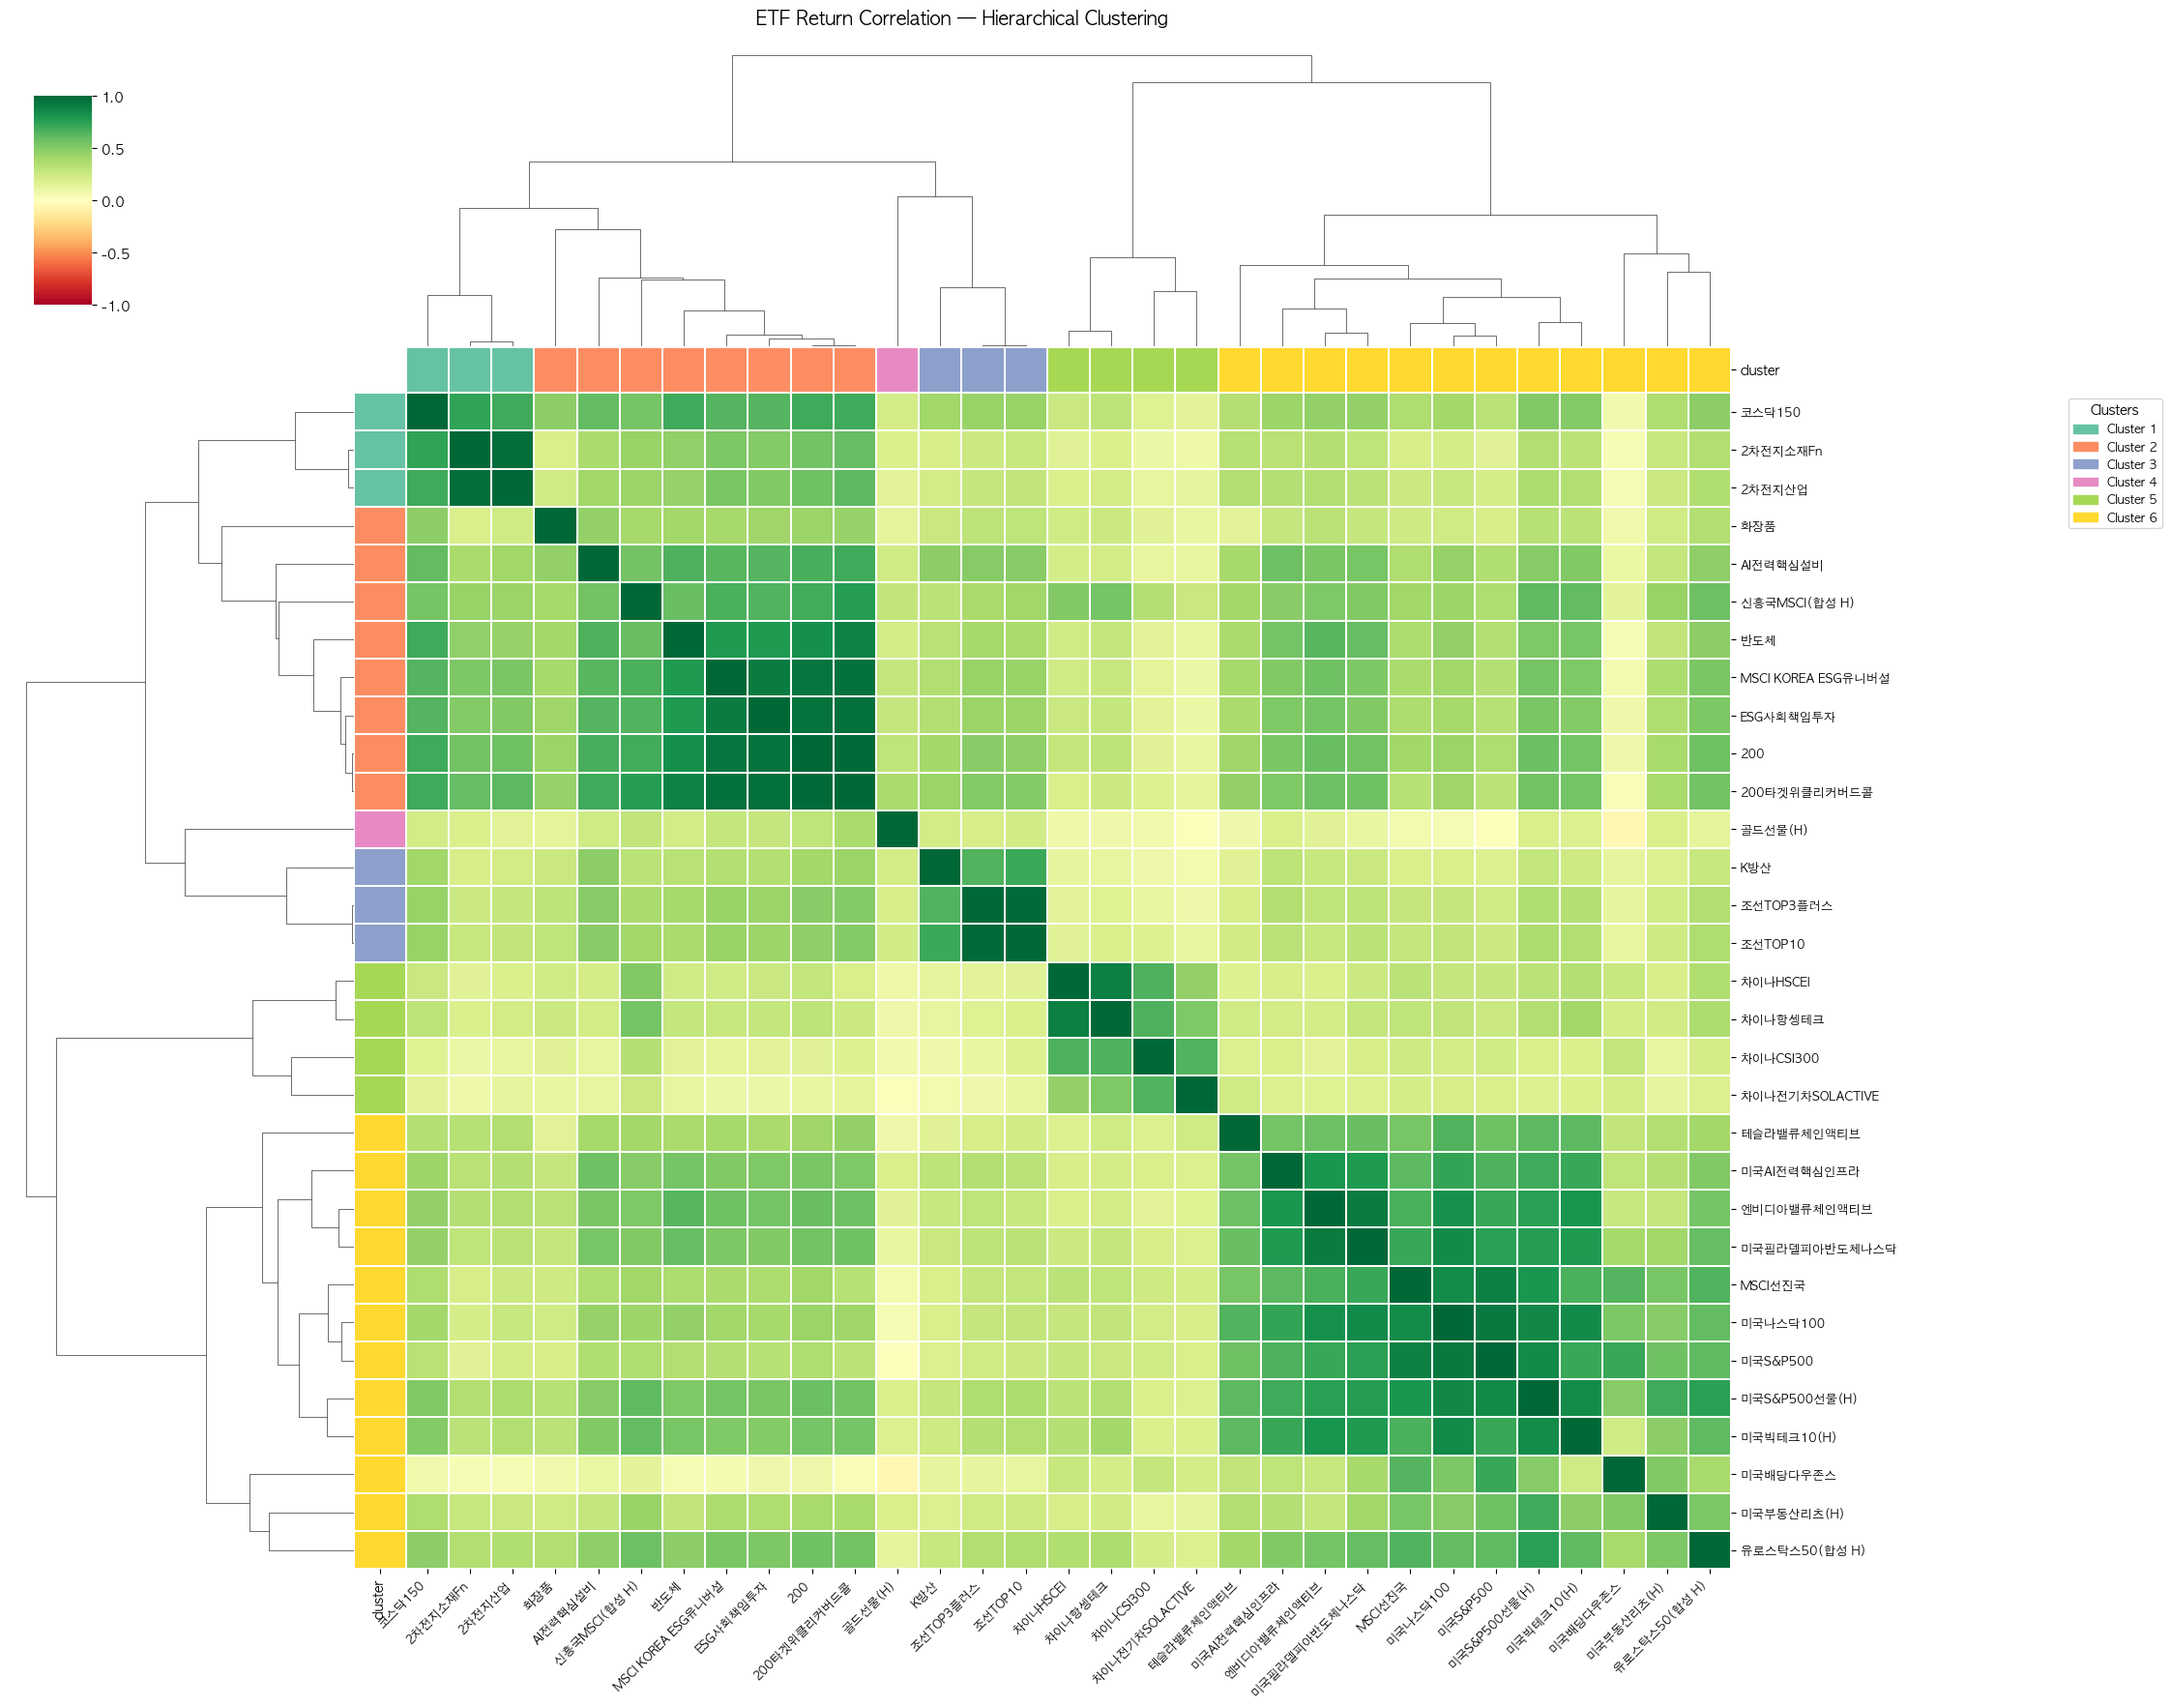


=== Cluster Summary ===

Cluster 1: ['KODEX 코스닥150', 'TIGER 2차전지소재Fn', 'KODEX 2차전지산업']

Cluster 2: ['KODEX 200', 'PLUS 신흥국MSCI(합성 H)', 'TIGER MSCI KOREA ESG유니버설', 'RISE ESG사회책임투자', 'TIGER 화장품', 'KODEX AI전력핵심설비', 'KODEX 200타겟위클리커버드콜', 'KODEX 반도체']

Cluster 3: ['SOL 조선TOP3플러스', 'PLUS K방산', 'TIGER 조선TOP10']

Cluster 4: ['KODEX 골드선물(H)']

Cluster 5: ['TIGER 차이나CSI300', 'TIGER 차이나HSCEI', 'TIGER 차이나항셍테크', 'TIGER 차이나전기차SOLACTIVE']

Cluster 6: ['KODEX 미국S&P500선물(H)', 'KODEX 미국나스닥100', 'KODEX MSCI선진국', 'KODEX 미국부동산리츠(H)', 'TIGER 유로스탁스50(합성 H)', 'KODEX 미국빅테크10(H)', 'KODEX 미국S&P500', 'ACE 테슬라밸류체인액티브', 'TIGER 미국배당다우존스', 'ACE 엔비디아밸류체인액티브', 'TIGER 미국필라델피아반도체나스닥', 'KODEX 미국AI전력핵심인프라']


In [11]:
# ── Hierarchical Clustering Heatmap ───────────────────────────────────────
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

matplotlib.rcParams["font.family"] = ["AppleGothic", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False

# 1. Log returns & correlation
log_returns = np.log(price / price.shift(1)).dropna(how="all")
corr = log_returns.corr()

# 2. Cluster
N_CLUSTERS = 6
dist = 1 - corr
condensed = squareform(dist.values, checks=False)
linkage_matrix = linkage(condensed, method="ward")
labels = fcluster(linkage_matrix, N_CLUSTERS, criterion="maxclust")
cluster_series = pd.Series(labels, index=corr.columns, name="cluster")

# 3. Short labels — strip fund family prefix so names fit on axes
def short_name(n):
    for prefix in ["KODEX ", "TIGER ", "RISE ", "PLUS ", "ACE ", "SOL "]:
        n = n.replace(prefix, "")
    return n[:18]

short_labels = [short_name(str(t)) for t in corr.index]
label_map = dict(zip(corr.index, short_labels))
corr_labeled = corr.rename(index=label_map, columns=label_map)
cluster_series_labeled = cluster_series.rename(index=label_map)

# 4. Cluster color bar
palette = sns.color_palette("Set2", N_CLUSTERS)
color_map = {i + 1: palette[i] for i in range(N_CLUSTERS)}
row_colors = cluster_series_labeled.map(color_map)

# 5. Clustermap — no per-cell numbers, color bar shows cluster membership
g = sns.clustermap(
    corr_labeled,
    row_linkage=linkage_matrix,
    col_linkage=linkage_matrix,
    row_colors=row_colors,
    col_colors=row_colors,
    cmap="RdYlGn",
    center=0, vmin=-1, vmax=1,
    annot=False,
    figsize=(20, 18),
    linewidths=0.15,
    cbar_pos=(0.02, 0.84, 0.03, 0.12),
)

# Rotate axis labels for readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right", fontsize=9)
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=9)

# Cluster legend
legend_handles = [
    mpatches.Patch(color=color_map[i + 1], label=f"Cluster {i + 1}")
    for i in range(N_CLUSTERS)
]
g.ax_heatmap.legend(
    handles=legend_handles,
    title="Clusters",
    bbox_to_anchor=(1.25, 1.0),
    loc="upper left",
    frameon=True,
    fontsize=9,
)

g.fig.suptitle("ETF Return Correlation — Hierarchical Clustering", fontsize=14, y=1.01)
plt.savefig("outputs/clustering_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Print cluster summary
print("\n=== Cluster Summary ===")
for c in sorted(cluster_series.unique()):
    members = cluster_series[cluster_series == c].index.tolist()
    print(f"\nCluster {c}: {members}")


In [12]:
# ── Risk Profile Constraints + Weight Allocation ──────────────────────────
# A/B/C type limits from regulatory filing (max allocation to high-risk ETFs)
RISK_LIMITS = {'A': 0.60, 'B': 0.51, 'C': 0.42}

# High-risk threshold: ETFs with annualized vol > 25% count toward the limit
VOL_THRESHOLD = 0.25

def compute_weights(ranks_df, risk_profile='B', top_n=10):
    """
    Convert frank scores to portfolio weights, applying the risk profile constraint.
    - Selects top_n ETFs by frank score.
    - Weights are proportional to inverse frank score (lower frank = higher weight).
    - If high-risk allocation (vol > 25%) exceeds the profile limit, high-risk
      weights are scaled down and the remainder redistributes to lower-risk ETFs.
    """
    if risk_profile not in RISK_LIMITS:
        raise ValueError(f"risk_profile must be one of {list(RISK_LIMITS.keys())}")

    limit = RISK_LIMITS[risk_profile]
    selected = ranks_df.head(top_n).copy()

    # Inverse frank weighting — lower frank score gets higher weight
    inv_frank = 1 / selected['frank']
    selected['weight'] = inv_frank / inv_frank.sum()
    selected['is_high_risk'] = selected['vol'] > VOL_THRESHOLD

    high_risk_w = selected.loc[selected['is_high_risk'], 'weight'].sum()

    # Scale down high-risk if over limit, redistribute to low-risk
    if high_risk_w > limit:
        scale = limit / high_risk_w
        selected.loc[selected['is_high_risk'], 'weight'] *= scale
        leftover = 1.0 - selected['weight'].sum()
        low_mask = ~selected['is_high_risk']
        if low_mask.any():
            low_w = selected.loc[low_mask, 'weight']
            selected.loc[low_mask, 'weight'] += leftover * (low_w / low_w.sum())
        else:
            selected['weight'] /= selected['weight'].sum()

    return selected[['momentum', 'vol', 'frank', 'is_high_risk', 'weight']]


# ── Preview weights at current rebalancing date ────────────────────────────
for profile in ['A', 'B', 'C']:
    w = compute_weights(rank2, risk_profile=profile, top_n=10)
    high = w.loc[w['is_high_risk'], 'weight'].sum()
    print(f"Profile {profile} (limit {RISK_LIMITS[profile]:.0%})  |  "
          f"high-risk alloc: {high:.1%}  |  weights sum: {w['weight'].sum():.4f}")
print()
display(compute_weights(rank2, risk_profile='B', top_n=10))


Profile A (limit 60%)  |  high-risk alloc: 58.9%  |  weights sum: 1.0000
Profile B (limit 51%)  |  high-risk alloc: 51.0%  |  weights sum: 1.0000
Profile C (limit 42%)  |  high-risk alloc: 42.0%  |  weights sum: 1.0000



,momentum,vol,frank,is_high_risk,weight
KODEX 미국S&P500,1.391,0.119032,21.89,False,0.129258
ACE 엔비디아밸류체인액티브,3.543,0.364828,22.74,True,0.090338
TIGER 미국필라델피아반도체나스닥,2.882,0.311624,22.76,True,0.090258
TIGER 차이나CSI300,1.488,0.143772,22.87,False,0.123719
KODEX 200,3.907,0.393474,23.73,True,0.086569
KODEX 미국나스닥100,1.545,0.151629,23.85,False,0.118636
KODEX MSCI선진국,1.366,0.119522,23.90,False,0.118387
KODEX 200타겟위클리커버드콜,3.251,0.368663,24.75,True,0.083001
RISE ESG사회책임투자,4.685,0.434402,25.70,True,0.079933
TIGER MSCI KOREA ESG유니버설,4.248,0.408161,25.71,True,0.079902


In [13]:
# ── Backtesting ────────────────────────────────────────────────────────────
def backtest(price_data, risk_profile='B', top_n=10, initial_value=100_000_000):
    """
    Simulate monthly rebalancing from the first month with enough history to today.
    Returns a pd.Series of portfolio value indexed by month-end date.
    """
    idx = pd.DatetimeIndex(price_data.index)
    month_ends = idx[idx.is_month_end].tolist()

    # Only start once at least MIN_HISTORY trading days exist
    valid_ends = []
    for d in month_ends:
        data_so_far = price_data[price_data.index <= str(d)]
        if data_so_far.notna().sum().max() >= MIN_HISTORY:
            valid_ends.append(d)

    if len(valid_ends) < 2:
        print("Not enough data to backtest.")
        return None

    values = {valid_ends[0]: float(initial_value)}

    for i in range(len(valid_ends) - 1):
        rebal_date  = valid_ends[i]
        next_date   = valid_ends[i + 1]

        try:
            ranks   = get_universe_ranks(price_data, rebal_date)
            weights = compute_weights(ranks, risk_profile, top_n)
        except Exception as e:
            values[next_date] = list(values.values())[-1]
            continue

        p0 = price_data[price_data.index <= str(rebal_date)].iloc[-1]
        p1 = price_data[price_data.index <= str(next_date)].iloc[-1]

        monthly_ret = sum(
            row['weight'] * (p1[etf] / p0[etf] - 1)
            for etf, row in weights.iterrows()
            if etf in p0.index and pd.notna(p0[etf]) and pd.notna(p1.get(etf))
        )
        values[next_date] = list(values.values())[-1] * (1 + monthly_ret)

    return pd.Series(values)


print("Running backtest for all 3 risk profiles — this may take ~2 minutes...")
portfolios = {}
for profile in ['A', 'B', 'C']:
    print(f"  Profile {profile}...")
    portfolios[profile] = backtest(price, risk_profile=profile, top_n=10, initial_value=100_000_000)
print(f"Done. {len(portfolios['B'])} months simulated per profile.")

Running backtest for all 3 risk profiles — this may take ~2 minutes...
  Profile A...
Rebalancing: 2022-02-28  |  Universe: 18/31 ETFs
  Excluded KODEX 미국나스닥100: only 220 trading days
  Excluded KODEX 미국S&P500: only 220 trading days
  Excluded TIGER 2차전지소재Fn: only 0 trading days
  Excluded SOL 조선TOP3플러스: only 0 trading days
  Excluded ACE 테슬라밸류체인액티브: only 0 trading days
  Excluded PLUS K방산: only 0 trading days
  Excluded TIGER 조선TOP10: only 0 trading days
  Excluded KODEX AI전력핵심설비: only 0 trading days
  Excluded TIGER 미국배당다우존스: only 0 trading days
  Excluded ACE 엔비디아밸류체인액티브: only 0 trading days
  Excluded TIGER 미국필라델피아반도체나스닥: only 220 trading days
  Excluded KODEX 미국AI전력핵심인프라: only 0 trading days
  Excluded KODEX 200타겟위클리커버드콜: only 0 trading days
Rebalancing: 2022-03-31  |  Universe: 18/31 ETFs
  Excluded KODEX 미국나스닥100: only 241 trading days
  Excluded KODEX 미국S&P500: only 241 trading days
  Excluded TIGER 2차전지소재Fn: only 0 trading days
  Excluded SOL 조선TOP3플러스: only 0 trading days
  E

=== Profile A (limit 60% high-risk) ===
  Total Return           +164.5%
  CAGR                   +26.3%
  Sharpe Ratio           1.73
  Max Drawdown           -15.9%
  Monthly Win Rate       75.8%
  Final Value (₩)        264,454,131

=== Profile B (limit 51% high-risk) ===
  Total Return           +158.4%
  CAGR                   +25.6%
  Sharpe Ratio           1.76
  Max Drawdown           -15.9%
  Monthly Win Rate       75.8%
  Final Value (₩)        258,392,535

=== Profile C (limit 42% high-risk) ===
  Total Return           +153.3%
  CAGR                   +25.0%
  Sharpe Ratio           1.79
  Max Drawdown           -15.9%
  Monthly Win Rate       75.8%
  Final Value (₩)        253,267,727



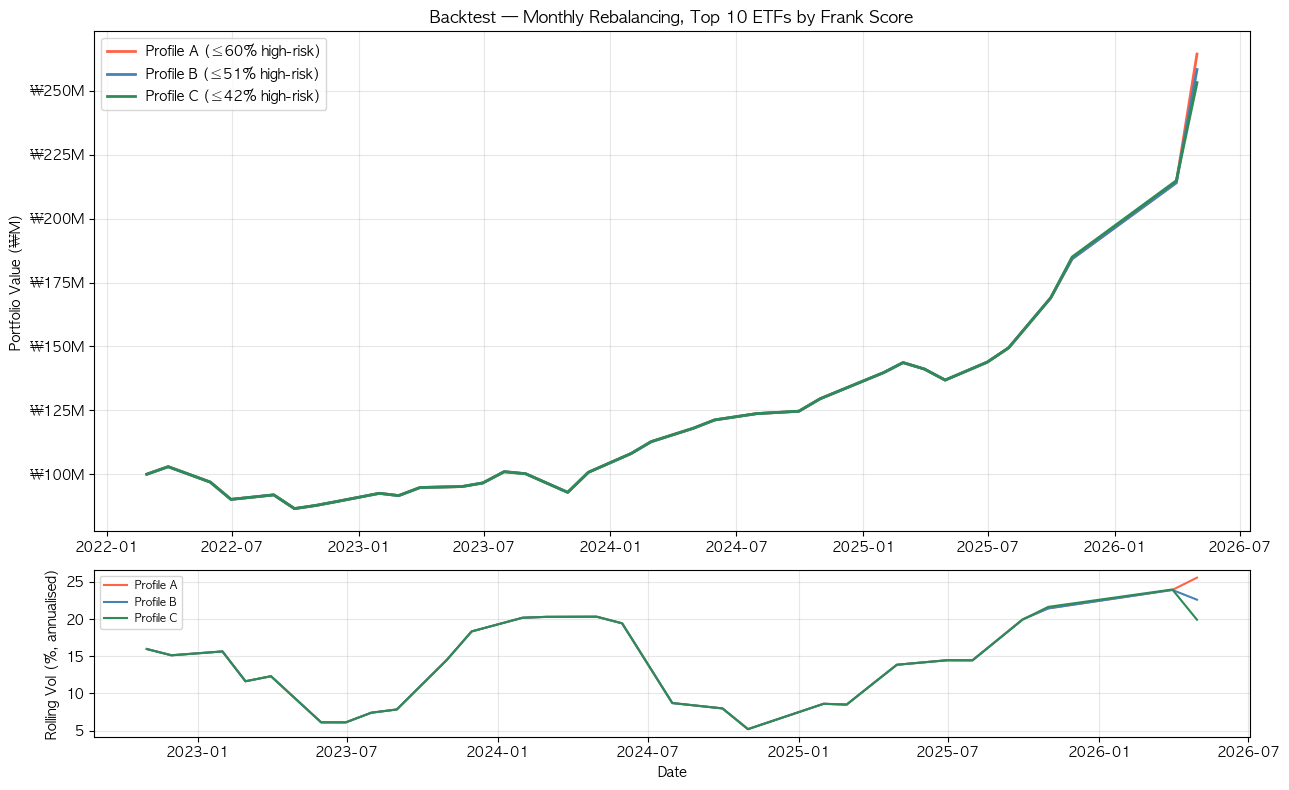

backtest_results.png 저장 완료!


In [14]:
# ── Backtest Results ───────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams["font.family"] = ["AppleGothic", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False

COLORS = {'A': 'tomato', 'B': 'steelblue', 'C': 'seagreen'}

def backtest_metrics(portfolio):
    total_return = portfolio.iloc[-1] / portfolio.iloc[0] - 1
    n_years = (portfolio.index[-1] - portfolio.index[0]).days / 365.25
    cagr = (1 + total_return) ** (1 / n_years) - 1

    monthly_returns = portfolio.pct_change().dropna()
    sharpe = (monthly_returns.mean() / monthly_returns.std()) * np.sqrt(12)

    rolling_max = portfolio.cummax()
    drawdown = (portfolio - rolling_max) / rolling_max
    max_dd = drawdown.min()

    win_rate = (monthly_returns > 0).sum() / len(monthly_returns)

    return {
        "Total Return":  f"{total_return:+.1%}",
        "CAGR":          f"{cagr:+.1%}",
        "Sharpe Ratio":  f"{sharpe:.2f}",
        "Max Drawdown":  f"{max_dd:.1%}",
        "Monthly Win Rate": f"{win_rate:.1%}",
        "Final Value (₩)": f"{portfolio.iloc[-1]:,.0f}",
    }

for profile in ['A', 'B', 'C']:
    metrics = backtest_metrics(portfolios[profile])
    print(f"=== Profile {profile} (limit {RISK_LIMITS[profile]:.0%} high-risk) ===")
    for k, v in metrics.items():
        print(f"  {k:<22} {v}")
    print()

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [3, 1]})

for profile, portfolio in portfolios.items():
    ax1.plot(portfolio.index, portfolio / 1e6, color=COLORS[profile], linewidth=2,
             label=f"Profile {profile} (≤{RISK_LIMITS[profile]:.0%} high-risk)")

ax1.set_ylabel("Portfolio Value (₩M)")
ax1.set_title("Backtest — Monthly Rebalancing, Top 10 ETFs by Frank Score")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"₩{x:.0f}M"))
ax1.legend()
ax1.grid(alpha=0.3)

# Rolling volatility (6-month window, annualized)
for profile, portfolio in portfolios.items():
    roll_vol = portfolio.pct_change().rolling(6).std() * (12 ** 0.5) * 100
    ax2.plot(roll_vol.index, roll_vol, color=COLORS[profile], linewidth=1.5, label=f"Profile {profile}")

ax2.set_ylabel("Rolling Vol (%, annualised)")
ax2.set_xlabel("Date")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("outputs/backtest_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("backtest_results.png 저장 완료!")